   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

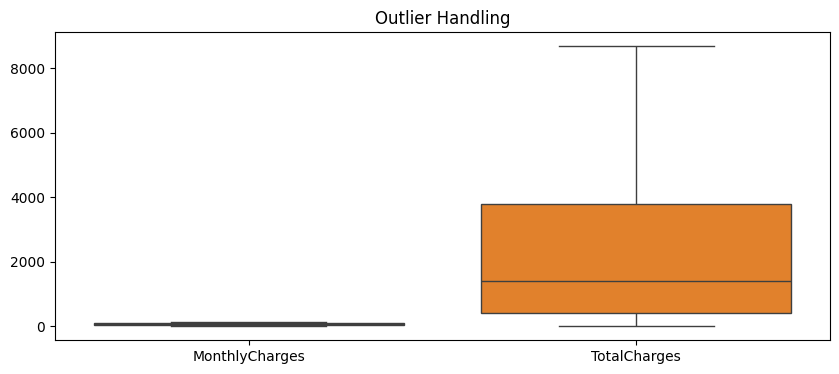


Training Data: (5634, 34)
Testing Data: (1409, 34)
Training Target: (5634,)
Testing Target: (1409,)

Cleaned dataset exported successfully!


In [2]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Import dataset

data = pd.read_csv("Telcom_Customer_Churn.csv")

# 2. Explore dataset

print(data.head())
print(data.tail())
print(data.shape)
print(data.columns)
print(data.info())
print(data.describe())
print(data.isnull().sum())

# 3. Handle missing values

# Remove extra spaces from column names
data.columns = data.columns.str.strip()

# Convert TotalCharges into numeric
data['TotalCharges'] = pd.to_numeric(
    data['TotalCharges'], errors='coerce'
)

# Fill missing TotalCharges for new customers
data.loc[
    (data['tenure'] == 0) & (data['TotalCharges'].isna()),
    'TotalCharges'
] = 0

# Fill remaining numerical missing values with median
num_cols = data.select_dtypes(include=np.number).columns

for col in num_cols:
    data[col] = data[col].fillna(data[col].median())

# Fill categorical missing values with mode
cat_cols = data.select_dtypes(include='object').columns

for col in cat_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

# 4. Remove duplicate records

print("Before removing duplicates:", len(data))

data = data.drop_duplicates()

print("After removing duplicates:", len(data))

# 5. Handle inconsistent data

for col in data.select_dtypes(include='object').columns:
    data[col] = data[col].str.strip()

# Standardize gender values
data['gender'] = data['gender'].str.title()

# Standardize Yes/No values
for col in data.select_dtypes(include='object').columns:
    data[col] = data[col].replace({
        'yes': 'Yes',
        'no': 'No'
    })

# 6. Convert columns to correct data types

data['SeniorCitizen'] = data['SeniorCitizen'].astype(int)
data['tenure'] = data['tenure'].astype(int)
data['MonthlyCharges'] = data['MonthlyCharges'].astype(float)
data['TotalCharges'] = data['TotalCharges'].astype(float)

print("\nData Types:")
print(data.dtypes)

# 7. Identify and handle outliers using IQR

for col in ['MonthlyCharges', 'TotalCharges']:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    data[col] = data[col].clip(lower, upper)

# Display box plots
plt.figure(figsize=(10, 4))
sns.boxplot(data=data[['MonthlyCharges', 'TotalCharges']])
plt.title("Outlier Handling")
plt.show()

# 8. Feature Engineering

# Create tenure group
data['TenureGroup'] = pd.cut(
    data['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['New', 'Medium', 'Long', 'Very Long']
)

# Calculate average monthly spending
data['AverageMonthlySpend'] = np.where(
    data['tenure'] > 0,
    data['TotalCharges'] / data['tenure'],
    0
)

# 9. Normalize data and encode categorical columns

# Convert Churn into numeric values
data['Churn'] = data['Churn'].map({
    'Yes': 1,
    'No': 0
})

# Save cleaned dataset
data.to_csv(
    "Cleaned_Telecom_Customer_Churn.csv",
    index=False
)

# Separate features and target
X = data.drop(['Churn', 'customerID'], axis=1)
y = data['Churn']

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

# 10. Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale numerical features
scale_cols = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges',
    'AverageMonthlySpend'
]

scaler = StandardScaler()

X_train[scale_cols] = scaler.fit_transform(
    X_train[scale_cols]
)

X_test[scale_cols] = scaler.transform(
    X_test[scale_cols]
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# 11. Export cleaned dataset

print("\nCleaned dataset exported successfully!")
